# RGC mosaics of all types

Supplementary figure: mosaics of all 31 resource-paper RGC types, in the style of the BC figure.
One column per type: name and n, example cell (side and top view), coverage of the whole field, and a
400 x 400 µm zoom with the cell outlines (200 x 200 µm in the BC figure; RGCs are much larger).

- **Order:** types sorted by median IPL depth (`perc_z_050`), OFF to ON, like the BC order t1 to t9.
- **Colors:** one color per type, made as for the BCs (interpolated palette over the depth order, reordered so
  that neighbours differ).
- **Coverage:** one shared color scale, capped at 8 ("8+"). The pooled ON-OFF DS cells (OODS, 4 directions) and
  ON DS EW7i (3 directions) would otherwise wash out all other types.
- **Hulls:** `hull_points`, as in `plot_RGCs.ipynb`. Cells whose hull is elongated by an unlabeled axon
  (`hull_shape_idx > 0.2`) are dropped from the mosaics, as in `plot_RGCs.ipynb`.
- **Morphologies:** thin black skeleton lines on the node circles; drawn back to front by IPL depth
  (`depth_sort=True`), so upper dendrites lie on top of lower ones.
- **Examples:** one fixed cell per type, chosen with the rules of `plot_RGCs.ipynb` (both labels strong, no
  unfixable errors, complete, fewest edge hits, closest to the type's tSNE centre). All skeletons are in
  `swc-examples.zip`.

# Imports

In [1]:
import os
import sys

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from scipy.spatial import ConvexHull

import cell_mosaics

In [2]:
sys.path.append("../utils")

import colors
import data_io
import rgc_labels
from mosaics import plot_coverage
from plot_cells import plot_cell_morphologies
from style import set_rc_params

In [3]:
set_rc_params()

# Settings

In [4]:
WIDE_EXTENT = (20, 1160, 30, 1170)  # whole field (square)
ZOOM_EXTENT = (380, 780, 420, 820)  # 400 x 400 µm, central part of the field
WIDE_RES, ZOOM_RES = 600, 800
COV_CAP = 8  # colour scale max; higher coverage is shown in the top colour ('8+')
SHAPE_IDX_MAX = 0.2  # as in plot_RGCs.ipynb: drop hulls with an unlabeled axon (elongated hull)
NCOLS = 8  # types per row
COL_W = 0.86  # column width in inches

# Example cell per type (short name -> segment ID)
EXAMPLES = {
    'FmOff': 720575940550638560,
    'FmOn': 720575940553070349,
    'M1': 720575940562833781,
    'M2': 720575940550970944,
    'M5': 720575940563567973,
    'M6': 720575940546692949,
    'OODS': 720575940571182764,
    'OODS-v': 720575940574776056,
    'e1ni': 720575940562588277,
    'e1no': 720575940560988508,
    'e25': 720575940551259072,
    'e28': 720575940561386122,
    'e2i': 720575940537472947,
    'e2o': 720575940557457623,
    'e3i': 720575940557458223,
    'e3o': 720575940555970202,
    'e4i': 720575940566885040,
    'e4on': 720575940555428546,
    'e5si': 720575940546217221,
    'e5ti': 720575940564157175,
    'e5to': 720575940569197936,
    'e6sn': 720575940583868027,
    'e6t': 720575940570079553,
    'e72': 720575940567950518,
    'e73': 720575940574278907,
    'e7i': 720575940551644967,
    'e7o': 720575940560426314,
    'sOFF-a': 720575940552408392,
    'sON-a': 720575940563641563,
    'tON-a': 720575940580688753,
    'tOff-a': 720575940563614445,
}

# Data

In [5]:
config = data_io.get_data_config()
version = config.get("version", None)
skel_dir = config.get("skel_dir", None)
file_path = data_io.get_file_path(config)

assert os.path.isdir(skel_dir), skel_dir
assert os.path.isfile(file_path), file_path

missing = [ct for ct, sid in EXAMPLES.items() if not os.path.isfile(os.path.join(skel_dir, f'{sid}.swc'))]
assert not missing, f'example skeletons missing in {skel_dir} (unpack swc-examples.zip): {missing}'

In [6]:
fig_dir = f'../figures/RGC/v{version}'
os.makedirs(fig_dir, exist_ok=True)

In [7]:
df_subset = pd.read_csv('RGC types for Figure.csv')
celltype2short = dict(zip(df_subset['Cell Type'], df_subset['Cell Type Short']))
show_types = {r['Cell Type'] for _, r in df_subset.iterrows() if str(r['Show']) == '1'}

In [8]:
df_all = data_io.load_df_all_neurons()
df = df_all[df_all.valid_celltype_final & df_all.celltype_final.isin(show_types)].copy()
df = data_io.restore_numpy_arrays(df)
del df_all

# all RGC labels come from the resource-paper RGC types sheet, so no cell is machine-only
assert (df.celltype_final_decision == rgc_labels.REFINED).all(), 'expected only refined RGC labels'
df['ct'] = df.celltype_final.map(celltype2short)

assert set(EXAMPLES) == set(df.ct), set(EXAMPLES) ^ set(df.ct)
assert all(df.loc[sid, 'ct'] == ct for ct, sid in EXAMPLES.items())
print(f'{len(df)} RGCs in {df.ct.nunique()} types')

RGC types sheet: 2980 / 3046 rows matched to the parquet (66 cells are not in the parquet); 2735 type and 190 class labels changed, 538 stale type labels removed


2980 RGCs in 31 types


Drop hulls that include an unlabeled axon from the mosaics (as in `plot_RGCs.ipynb`)

In [9]:
df['hull_shape_idx'] = ((df.hull_perimeter + 10) / (df.hull_diameter + 10)) / np.pi - 1
flagged = df[df.hull_shape_idx > SHAPE_IDX_MAX]
print(f'Dropping {len(flagged)} cells with hull_shape_idx > {SHAPE_IDX_MAX} from the mosaics:')
print(flagged.ct.value_counts().to_dict())
df_mos = df.drop(flagged.index)

Dropping 42 cells with hull_shape_idx > 0.2 from the mosaics:
{'M5': 6, 'FmOn': 4, 'e1no': 4, 'e5ti': 3, 'e7i': 3, 'M1': 3, 'FmOff': 2, 'sON-a': 2, 'e4i': 2, 'sOFF-a': 2, 'M6': 2, 'OODS': 2, 'e5si': 1, 'e25': 1, 'e4on': 1, 'e6sn': 1, 'e6t': 1, 'e28': 1, 'tON-a': 1}


Type order (median IPL depth, OFF -> ON) and colours

In [10]:
depth_order = df.groupby('ct').perc_z_050.median().sort_values(ascending=False).index.tolist()
print(depth_order)

cols = colors.reorder_colors_for_distinction(colors.interpolate_colors(n=len(depth_order), plot=False), n_neighbors=4)
label2color = dict(zip(depth_order, cols))

['M1', 'e1no', 'e1ni', 'e2o', 'e25', 'e2i', 'FmOff', 'sOFF-a', 'e3o', 'e3i', 'e28', 'OODS-v', 'OODS', 'tOff-a', 'e4on', 'e4i', 'e5to', 'FmOn', 'e5ti', 'e5si', 'e6t', 'tON-a', 'e6sn', 'e73', 'e7o', 'e7i', 'e72', 'sON-a', 'M6', 'M5', 'M2']


Field outline: convex hull of all RGC hulls

In [11]:
pts = np.vstack(df.hull_points.values)[:, :2]
hull = ConvexHull(pts)
outline = pts[np.append(hull.vertices, hull.vertices[0])]

# Coverage maps

In [12]:
mappers = {}
for ct in depth_order:
    for extent, res in [(WIDE_EXTENT, WIDE_RES), (ZOOM_EXTENT, ZOOM_RES)]:
        m = cell_mosaics.CoverageDensityMapper(field_bounds=extent, resolution=res)
        m.add_multiple_polygons(df_mos.loc[df_mos.ct == ct, 'hull_points'])
        mappers[(ct, extent)] = m

c_max_data = max(int(mappers[(ct, WIDE_EXTENT)].coverage_count.max()) for ct in depth_order)
c_max = min(c_max_data, COV_CAP)
print(f'max coverage {c_max_data}, colour scale capped at {c_max}')

max coverage 15, colour scale capped at 8


# Figure

c:\Users\joesterle\github\eyewire2\eyewire2-figures\notebooks\../utils\mosaics.py:42: UserWarning: max_val too small. Should be >=9
  warnings.warn(f'max_val too small. Should be >={int(np.max(coverage_count))}')


c:\Users\joesterle\github\eyewire2\eyewire2-figures\notebooks\../utils\mosaics.py:42: UserWarning: max_val too small. Should be >=14
  warnings.warn(f'max_val too small. Should be >={int(np.max(coverage_count))}')


c:\Users\joesterle\github\eyewire2\eyewire2-figures\notebooks\../utils\mosaics.py:42: UserWarning: max_val too small. Should be >=15
  warnings.warn(f'max_val too small. Should be >={int(np.max(coverage_count))}')
c:\Users\joesterle\github\eyewire2\eyewire2-figures\notebooks\../utils\mosaics.py:42: UserWarning: max_val too small. Should be >=10
  warnings.warn(f'max_val too small. Should be >={int(np.max(coverage_count))}')


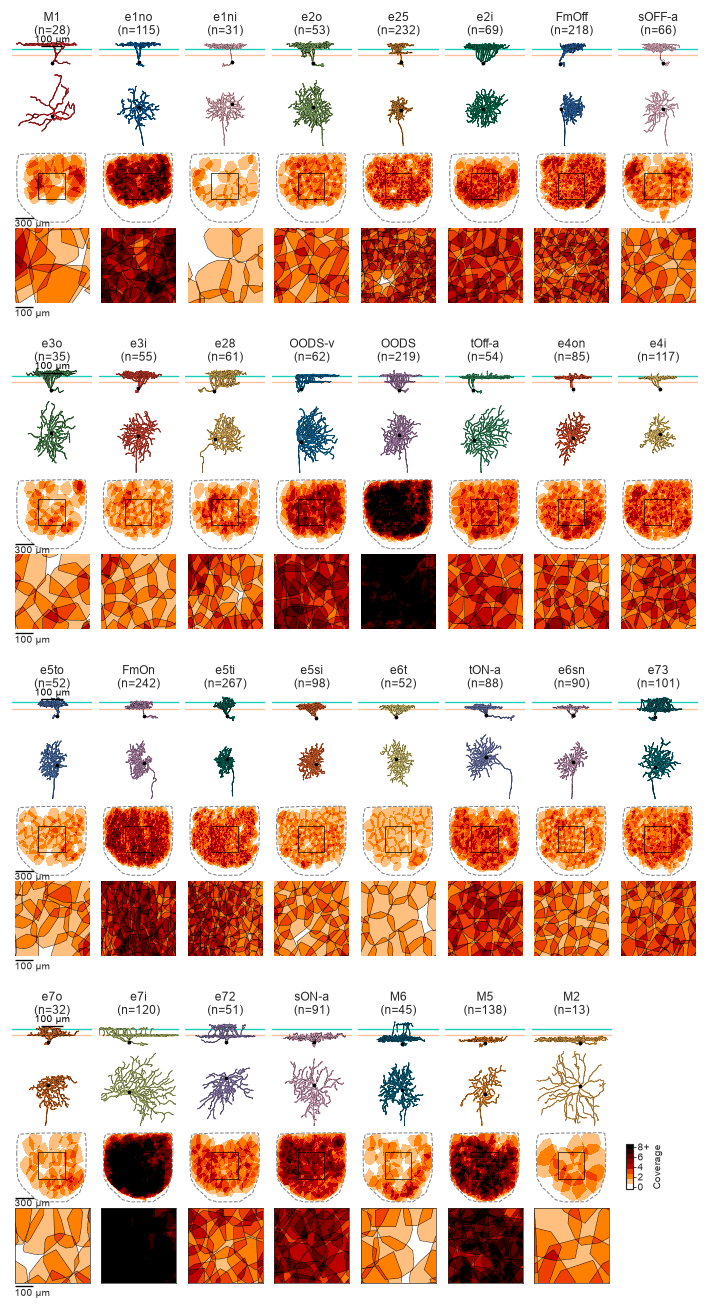

In [13]:
types = depth_order
blocks = [types[i:i + NCOLS] for i in range(0, len(types), NCOLS)]
rad = df.loc[[EXAMPLES[ct] for ct in types], 'hull_diameter'].max() / 2 * 1.05
zlim = (-24, 28)
row_h = [0.3, 0.36 * COL_W, COL_W, COL_W, COL_W]  # title, xz (z stretched ~2x), xy, whole field, zoom
block_h = sum(row_h)

fig = plt.figure(figsize=(NCOLS * COL_W + 0.5, len(blocks) * (block_h + 0.25)))
outer = fig.add_gridspec(len(blocks), 1, hspace=0.12)
im = None
for b, block in enumerate(blocks):
    gs = outer[b].subgridspec(5, NCOLS, height_ratios=row_h, hspace=0.06, wspace=0.08)
    axs = np.array([[fig.add_subplot(gs[r, c]) for c in range(NCOLS)] for r in range(5)])
    for ax in axs.flat:
        ax.set(xticks=[], yticks=[])
        for s in ax.spines.values():
            s.set_visible(False)

    # morphologies (side + top view)
    n = len(block)
    plot_cell_morphologies(
        rows=df.loc[[EXAMPLES[ct] for ct in block]], rad=rad, skel_dir=skel_dir, size=100, fig=fig, axs=axs[1:3, :n],
        color_list=[label2color[ct] for ct in block], show_on_tsne=False, zlim=zlim,
        edge_lw=0.15, node_lw=0.4, soma_marker_size=2, soma_linewidth=0.2, sb_fontsize=6, depth_sort=True)
    for ax in axs[1:3].flat:
        ax.set(xticks=[], yticks=[], xlabel=None, ylabel=None)
        for s in ax.spines.values():
            s.set_visible(False)

    for j, ct in enumerate(block):
        n_cells = int((df.ct == ct).sum())
        axs[0, j].text(0.5, 0.0, f'{ct}\n(n={n_cells:,})', ha='center', va='bottom', fontsize=7,
                       transform=axs[0, j].transAxes)

        # whole-field coverage, with the field outline and the zoom box
        ax = axs[3, j]
        _, _, im = plot_coverage(mappers[(ct, WIDE_EXTENT)].coverage_count, extent=WIDE_EXTENT, ax=ax,
                                 colormap='gist_heat_r', min_val=0, max_val=c_max, plot_cbar=False)
        ax.plot(*outline.T, c='gray', ls='--', lw=0.6, clip_on=False)
        x0, x1, y0, y1 = ZOOM_EXTENT
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='k', lw=0.4))

        # zoom: coverage + cell outlines
        ax = axs[4, j]
        m = mappers[(ct, ZOOM_EXTENT)]
        plot_coverage(m.coverage_count, cell_outlines=m.cell_outlines, extent=ZOOM_EXTENT, ax=ax,
                      colormap='gist_heat_r', min_val=0, max_val=c_max, plot_cbar=False, edge_kws=dict(lw=0.25))
        for s in ax.spines.values():
            s.set_visible(True)
            s.set_linewidth(0.4)

    for ax in axs[3:].flat:
        ax.set(xticks=[], yticks=[], xlabel=None, ylabel=None)
    for ax in axs[:, n:].flat:
        ax.set_visible(False)

    # scale bars (first column): whole field inside the empty lower-left corner, zoom below the panel
    x0, x1, y0, y1 = WIDE_EXTENT
    yb = y0 + 0.09 * (y1 - y0)
    axs[3, 0].plot([x0, x0 + 300], [yb, yb], c='k', lw=0.8, solid_capstyle='butt')
    axs[3, 0].text(x0, yb - 0.02 * (y1 - y0), '300 µm', fontsize=6, va='top', ha='left')
    x0, x1, y0, y1 = ZOOM_EXTENT
    yb = y0 - 0.05 * (y1 - y0)
    axs[4, 0].plot([x0, x0 + 100], [yb, yb], c='k', lw=0.8, solid_capstyle='butt', clip_on=False)
    axs[4, 0].text(x0, yb - 0.03 * (y1 - y0), '100 µm', fontsize=6, va='top', ha='left')
    last_axs = axs

# one colorbar: in the first free column of the last row, else right of the last zoom panel
n_last = len(blocks[-1])
if n_last < NCOLS:
    pos = last_axs[3, n_last].get_position()
    cax = fig.add_axes((pos.x0 + 0.1 * pos.width, pos.y0 + 0.2 * pos.height, 0.08 * pos.width, 0.6 * pos.height))
else:
    pos = last_axs[4, -1].get_position()
    cax = fig.add_axes((pos.x1 + 0.08 * pos.width, pos.y0 + 0.15 * pos.height, 0.07 * pos.width, 0.7 * pos.height))
cb = fig.colorbar(im, cax=cax, orientation='vertical')
ticks = np.arange(0, c_max + 1, 2 if c_max > 5 else 1)
cb.set_ticks(ticks)
cb.set_ticklabels([f'{t}+' if (t == c_max and c_max_data > c_max) else str(t) for t in ticks])
cb.ax.tick_params(labelsize=6, length=2, pad=1)
cb.set_label('Coverage', fontsize=6, labelpad=2)

for ext in ('svg', 'png'):
    fig.savefig(os.path.join(fig_dir, f'rgc-mosaics-all.{ext}'), dpi=400, bbox_inches='tight')
plt.show()